# Artificial Neural Networks (AIC 380)
**Student Name:** Abdullah Ghaffar  
**Registration No:** FA23-BAI-059  

---
## Lab 06 (Manual Lab 10): Introduction to Keras & Implementation of ANN

### Objective:
Building and training Multi-Layer Perceptrons (MLPs) using TensorFlow/Keras Sequential API: Dense layers, activations (ReLU, Sigmoid, Softmax), optimizers (Adam, SGD, RMSprop), and extensive hyperparameter tuning.


### Activity 1: Building and Training Baseline ANN on MNIST


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

# Load and preprocess MNIST dataset (using subset for speed)
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train[:10000] / 255.0
y_train = to_categorical(y_train[:10000], 10)
x_test = x_test[:2000] / 255.0
y_test = to_categorical(y_test[:2000], 10)

# Build baseline architecture
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

history = model.fit(x_train, y_train, epochs=5, batch_size=64, validation_split=0.2, verbose=1)
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Baseline Test Accuracy: {test_acc * 100:.2f}%")


       0/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   24576/11490434 ━━━━━━━━━━━━━━━━━━━━ 26s 2us/step

   49152/11490434 ━━━━━━━━━━━━━━━━━━━━ 46s 4us/step

   81920/11490434 ━━━━━━━━━━━━━━━━━━━━ 55s 5us/step

  172032/11490434 ━━━━━━━━━━━━━━━━━━━━ 30s 3us/step

...

 29/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9561 - loss: 0.1427 

 61/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9597 - loss: 0.1333

 96/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9619 - loss: 0.1274

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9664 - loss: 0.1162 - val_accuracy: 0.9310 - val_loss: 0.2337


Baseline Test Accuracy: 91.85%


### Activity 2: Systematic Experiments on Neural Architectures and Optimizers


In [2]:
# Experiment 1: Change number of neurons (256 -> 128)
exp1_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])
exp1_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h1 = exp1_model.fit(x_train, y_train, epochs=3, batch_size=64, validation_split=0.2, verbose=0)
loss1, acc1 = exp1_model.evaluate(x_test, y_test, verbose=0)
print(f"Exp 1 (Wider Layers 256-128) Accuracy: {acc1 * 100:.2f}%")

# Experiment 2: Change activation function to Sigmoid
exp2_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='sigmoid'),
    Dense(64, activation='sigmoid'),
    Dense(10, activation='softmax')
])
exp2_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h2 = exp2_model.fit(x_train, y_train, epochs=3, batch_size=64, validation_split=0.2, verbose=0)
loss2, acc2 = exp2_model.evaluate(x_test, y_test, verbose=0)
print(f"Exp 2 (Sigmoid Activation) Accuracy: {acc2 * 100:.2f}%")

# Experiment 3: Change optimizer to SGD
exp3_model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])
exp3_model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])
h3 = exp3_model.fit(x_train, y_train, epochs=3, batch_size=64, validation_split=0.2, verbose=0)
loss3, acc3 = exp3_model.evaluate(x_test, y_test, verbose=0)
print(f"Exp 3 (SGD Optimizer) Accuracy: {acc3 * 100:.2f}%")


Exp 1 (Wider Layers 256-128) Accuracy: 92.50%


Exp 2 (Sigmoid Activation) Accuracy: 86.70%


Exp 3 (SGD Optimizer) Accuracy: 79.20%


### Graded Lab Task 1: Building & Training Neural Network for Wine Quality Prediction


D:\Softwares\Python 3.10.11\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Wine Quality Model Test Accuracy: 100.00%


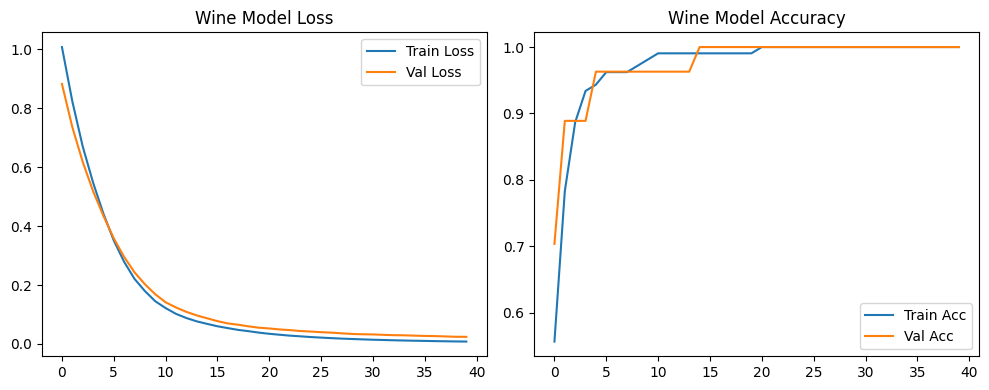

In [3]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Dropout

# Load Wine dataset (representing multi-class wine prediction)
wine = load_wine()
X_w, y_w = wine.data, wine.target
y_w_cat = to_categorical(y_w, 3)

X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(X_w, y_w_cat, test_size=0.25, random_state=42)

scaler_w = StandardScaler()
X_tr_w = scaler_w.fit_transform(X_tr_w)
X_te_w = scaler_w.transform(X_te_w)

# Build Wine Classifier
wine_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_w.shape[1],)),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

wine_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
wine_hist = wine_model.fit(X_tr_w, y_tr_w, epochs=40, batch_size=16, validation_split=0.2, verbose=0)

w_loss, w_acc = wine_model.evaluate(X_te_w, y_te_w, verbose=0)
print(f"Wine Quality Model Test Accuracy: {w_acc * 100:.2f}%")

# Training & Validation Curves
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(wine_hist.history['loss'], label='Train Loss')
plt.plot(wine_hist.history['val_loss'], label='Val Loss')
plt.title('Wine Model Loss')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(wine_hist.history['accuracy'], label='Train Acc')
plt.plot(wine_hist.history['val_accuracy'], label='Val Acc')
plt.title('Wine Model Accuracy')
plt.legend()
plt.tight_layout()
plt.show()


### Graded Lab Task 2: Enhancing Network Performance (Tuning & Regularization)


In [4]:
# Apply Regularization (Dropout), deeper capacity, and RMSprop optimizer with learning rate tuning
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.regularizers import l2

enhanced_model = Sequential([
    Dense(128, activation='relu', kernel_regularizer=l2(0.001), input_shape=(X_w.shape[1],)),
    Dropout(0.3),
    Dense(64, activation='relu', kernel_regularizer=l2(0.001)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(3, activation='softmax')
])

enhanced_model.compile(
    optimizer=RMSprop(learning_rate=0.005),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

enh_hist = enhanced_model.fit(X_tr_w, y_tr_w, epochs=50, batch_size=16, validation_split=0.2, verbose=0)
enh_loss, enh_acc = enhanced_model.evaluate(X_te_w, y_te_w, verbose=0)

print(f"Initial Wine Model Accuracy: {w_acc * 100:.2f}%")
print(f"Enhanced Model with L2 Regularization & Dropout Accuracy: {enh_acc * 100:.2f}%")


Initial Wine Model Accuracy: 100.00%
Enhanced Model with L2 Regularization & Dropout Accuracy: 97.78%
